# Assignment 3 — Regularization and Stability

*Statistical Methods for Machine Learning, A.Y. 2025/26, Università degli Studi di Milano.*

**Question.** Bousquet & Elisseeff (2002) show that an algorithm whose output barely changes when
one training point is removed (*stable*) must have a small generalisation gap. For ridge regression
the stability constant shrinks like $1/(\lambda n)$. We check this empirically:

1. does a larger regularisation strength $\lambda$ make ridge regression more stable?
2. do more stable models have a smaller gap between test and training error?
3. what does stability **not** tell us (the bias side of the trade-off)?

All learning code is written from scratch in the `regstab` package (numpy only); this notebook just
runs the experiments and draws the figures. Run it with *Restart & Run All*.

## 1. Setup

`sys.path` gets the project root so that `import regstab` works when the notebook is run from
inside `notebooks/`. Every setting (seed, $\lambda$ grid, sizes) lives in `regstab/config.py`.

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # project root -> makes `regstab` importable

import numpy as np
from regstab import config, plotting
from regstab.data import diabetes_split, load_diabetes_raw, make_synthetic, make_true_weights
from regstab.experiments import lambda_sweep, size_sweep

%matplotlib inline
print("seed:", config.SEED, "| repetitions R:", config.R,
      "| lambda grid:", f"{config.LAMBDAS[0]:.0e} ... {config.LAMBDAS[-1]:.0e} ({len(config.LAMBDAS)} values)")

seed: 2026 | repetitions R: 20 | lambda grid: 1e-05 ... 1e+02 (30 values)


## 2. Datasets — and why their conditioning matters

* **Synthetic**: $x \sim \mathcal N(0,\Sigma)$ with $\Sigma_{ij}=0.9^{|i-j|}$, $d=30$, $y = x^\top w^* + \varepsilon$,
  $\varepsilon\sim\mathcal N(0,1)$. Training size $n=40$, fresh test set of 2000 points. The best possible
  test MSE (Bayes error) is $\sigma^2 = 1$.
* **Diabetes** (442 patients, 10 features): random test set of 142 patients and a training subsample of
  $n=50$ from the rest; a contrast run uses all $n=300$ remaining patients.

The quantity that drives everything below is the **condition number** of $Z^\top Z$ (standardised
training features): the ratio between its largest and smallest eigenvalue. OLS divides by the
eigenvalues, so a huge condition number means a tiny change in the data can move the OLS solution a
lot. Ridge adds $n\lambda$ to every eigenvalue, which caps this amplification.

In [2]:
def cond_ZtZ(X):
    # Standardise with the training set's own statistics, as the models do.
    Z = (X - X.mean(0)) / X.std(0)
    ev = np.linalg.eigvalsh(Z.T @ Z)
    return ev.max() / ev.min(), ev.min()

rng = np.random.default_rng(config.SEED)
w_star = make_true_weights(config.SYN_D, rng)
X_syn, _ = make_synthetic(config.SYN_N_TRAIN, w_star, config.SYN_RHO, config.SYN_SIGMA, rng)
X_all, y_all = load_diabetes_raw()
X_d50, *_ = diabetes_split(X_all, y_all, config.DIAB_N_TRAIN, config.DIAB_N_TEST, rng)
X_d300, *_ = diabetes_split(X_all, y_all, config.DIAB_N_TRAIN_FULL, config.DIAB_N_TEST, rng)

for name, X in [("synthetic, n=40, d=30", X_syn), ("Diabetes, n=50, d=10", X_d50), ("Diabetes, n=300, d=10", X_d300)]:
    k, ev_min = cond_ZtZ(X)
    print(f"{name:24s} condition number of Z^T Z = {k:10.1f}   smallest eigenvalue = {ev_min:8.4f}")

synthetic, n=40, d=30    condition number of Z^T Z =     5469.9   smallest eigenvalue =   0.0969
Diabetes, n=50, d=10     condition number of Z^T Z =     1184.7   smallest eigenvalue =   0.1796
Diabetes, n=300, d=10    condition number of Z^T Z =      505.3   smallest eigenvalue =   2.4187


## 3. Run the experiments

For every repetition (new random split or new synthetic draw) and every $\lambda$, `loo_stability`
fits the model on the full training set $S$ and then **refits it $n$ times**, each time on $S$ without
one point. It records train/test MSE and three stability metrics measured on the fixed test set:

* `mean_pred_change` $= \frac1n\sum_i \frac1m\sum_j |f_S(x'_j) - f_{S\setminus i}(x'_j)|$ (main metric);
* `max_pred_change` $= \max_i \max_j |f_S(x'_j) - f_{S\setminus i}(x'_j)|$ (proxy for the paper's uniform stability $\beta$);
* `mean_loss_change`: same as the first, on the squared loss instead of the prediction.

| run | dataset | $n_\text{train}$ | purpose |
|---|---|---|---|
| A | synthetic | 40 | main |
| B | Diabetes | 50 | main |
| C | Diabetes | 300 | contrast: plenty of data |
| D | synthetic | 35 … 500 | extension: effect of dataset size |

This takes about a minute and a half (≈ 400 000 small model fits).

In [3]:
t0 = time.time()
res_syn = lambda_sweep("synthetic", config.SYN_N_TRAIN, config.LAMBDAS, config.R, config.SEED)
res_d50 = lambda_sweep("diabetes", config.DIAB_N_TRAIN, config.LAMBDAS, config.R, config.SEED)
res_d300 = lambda_sweep("diabetes", config.DIAB_N_TRAIN_FULL, config.LAMBDAS, config.R, config.SEED)
res_size = size_sweep(config.SIZE_N_VALUES, config.SIZE_LAMBDAS, config.R, config.SEED)
print(f"all experiments done in {time.time() - t0:.0f} s")

main = {"Synthetic": res_syn, "Diabetes": res_d50}
FIG = config.FIG_DIR

all experiments done in 82 s


## 4. Figures

Shared conventions: solid line = mean over the 20 repetitions, shaded band = ±1 standard deviation,
**dashed** line = OLS ($\lambda=0$, drawn as a horizontal reference because 0 cannot sit on a log axis),
**dotted** gray = theoretical reference.

### Figure 1 — Stability vs regularisation

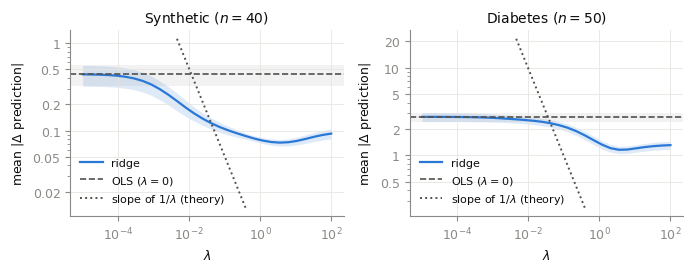

In [4]:
plotting.plot_stability_vs_lambda(main, FIG / "fig1_stability_vs_lambda.pdf");

**What to notice.** _(filled in after the run)_

### Figure 2 — Train and test error vs regularisation

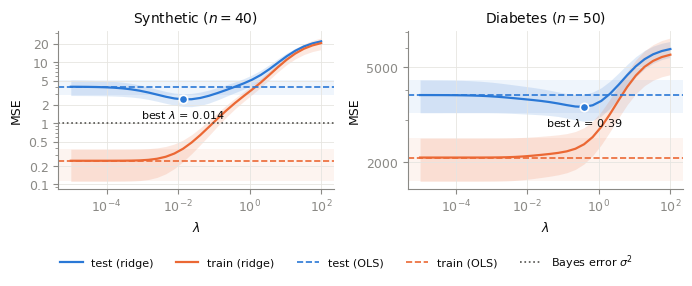

In [5]:
plotting.plot_error_vs_lambda(main, FIG / "fig2_error_vs_lambda.pdf",
                              bayes_mse={"Synthetic": config.SYN_SIGMA**2, "Diabetes": None});

**What to notice.** _(filled in after the run)_

### Figure 3 — Stability vs generalisation gap

Each point is one $\lambda$ (colour), averaged over repetitions; the cross is OLS. If stability
controls generalisation, points to the left (more stable) should have a smaller gap.

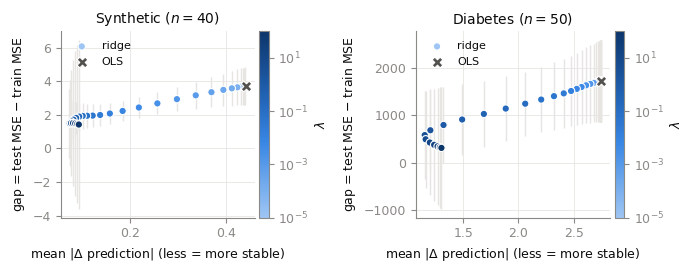

In [6]:
plotting.plot_stability_vs_gap(main, FIG / "fig3_stability_vs_gap.pdf");

**What to notice.** _(filled in after the run)_

### Figure 4 — Extension: effect of the training-set size

Synthetic data, $d=30$, $n$ from 35 to 500, four values of $\lambda$ plus OLS. The bound predicts
ridge stability $\propto 1/n$ at fixed $\lambda$.

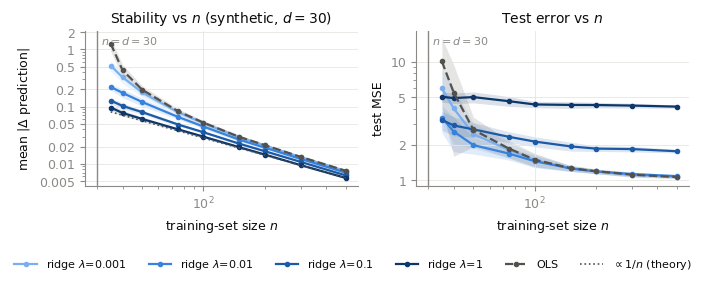

In [7]:
plotting.plot_size_sweep(res_size, config.SYN_D, FIG / "fig4_size_sweep.pdf");

**What to notice.** _(filled in after the run)_

### Figure 5 — Contrast: Diabetes with a small vs a large training set

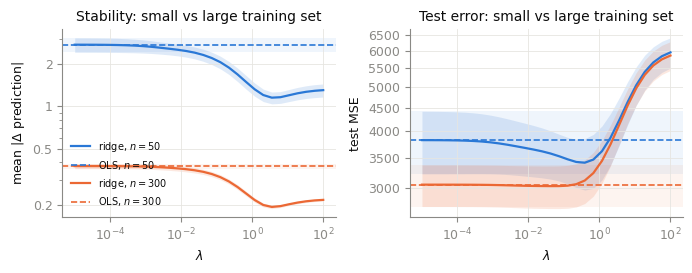

In [8]:
plotting.plot_contrast(res_d50, res_d300, FIG / "fig5_contrast_diabetes.pdf");

**What to notice.** _(filled in after the run)_

### Figure 6 — Do the other two stability metrics agree?

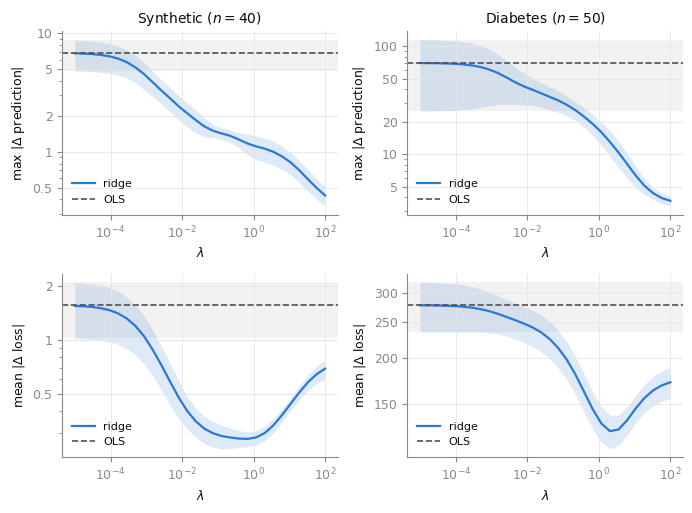

In [9]:
plotting.plot_metric_agreement(main, FIG / "fig6_metric_agreement.pdf");

**What to notice.** _(filled in after the run)_

## 5. Summary table — OLS vs best-$\lambda$ ridge

"Best" is the $\lambda$ with the lowest mean test MSE in the sweep. This is a **descriptive** summary
of the curves, not a model-selection procedure (picking $\lambda$ on the test set is optimistic).
Values are mean ± std over the 20 repetitions; "stability" is `mean_pred_change`.

In [10]:
rows = plotting.summary_rows({"Synthetic": res_syn, "Diabetes ($n=50$)": res_d50, "Diabetes ($n=300$)": res_d300})
for r in rows:
    fmt = lambda v: "   --" if v is None else f"{v[0]:9.3f} ± {v[1]:7.3f}"
    print(f"{r['dataset']:20s} {r['model'][:5]:5s} lam={r['lam']:<8.2g} train={fmt(r['train_mse'])} "
          f"test={fmt(r['test_mse'])} gap={fmt(r['gap'])} stab={fmt(r['mean_pred_change'])} R2={fmt(r['test_r2'])}")

(FIG / "summary_table.tex").write_text(plotting.rows_to_latex(rows) + "\n")
print("\nLaTeX table written to", FIG / "summary_table.tex")

Synthetic            OLS   lam=0        train=    0.244 ±   0.132 test=    3.973 ±   1.122 gap=    3.729 ±   1.118 stab=    0.441 ±   0.119 R2=   --
Synthetic            Ridge lam=0.014    train=    0.383 ±   0.148 test=    2.464 ±   0.578 gap=    2.081 ±   0.614 stab=    0.157 ±   0.029 R2=   --
Diabetes ($n=50$)    OLS   lam=0        train= 2095.571 ± 429.453 test= 3822.877 ± 599.310 gap= 1727.307 ± 863.722 stab=    2.746 ±   0.323 R2=    0.358 ±   0.106
Diabetes ($n=50$)    Ridge lam=0.39     train= 2381.446 ± 410.391 test= 3410.932 ± 439.873 gap= 1029.485 ± 702.328 stab=    1.687 ±   0.185 R2=    0.429 ±   0.057
Diabetes ($n=300$)   OLS   lam=0        train= 2820.909 ± 147.628 test= 3053.517 ± 318.954 gap=  232.608 ± 465.445 stab=    0.376 ±   0.016 R2=    0.489 ±   0.038
Diabetes ($n=300$)   Ridge lam=0.042    train= 2846.504 ± 149.677 test= 3030.785 ± 324.214 gap=  184.281 ± 473.327 stab=    0.342 ±   0.015 R2=    0.493 ±   0.036

LaTeX table written to /Users/preciousprince/Desk